In [1]:
import numpy as np

In [2]:
import numpy as np


class PositionalEncoder():
    """ An implementation of positional encoding.

    Attributes:
        d_model (int): The number of embedding dimensions in the learned
            embeddings. This is used to determine the length of the positional
            encoding vectors, which make up the rows of the positional encoding
            matrix.
        max_length (int): The maximum sequence length in the transformer. This
            is used to determine the size of the positional encoding matrix.
        rounding (int): The number of decimal places to round each of the
            values to in the output positional encoding matrix.
    """

    def __init__(self, d_model, max_length, rounding):
        self.d_model = d_model
        self.max_length = max_length
        self.rounding = rounding


    def generate_positional_encoding(self):
        """ Generate positional information to add to inputs for encoding.

        The positional information is generated using the number of embedding
        dimensions (d_model), the maximum length of the sequence (max_length),
        and the number of decimal places to round to (rounding). The output
        matrix generated is of size (max_length X embedding_dim), where each
        row is the positional information to be added to the learned
        embeddings, and each column is an embedding dimension.
        """

        position = np.arange(0, self.max_length).reshape(self.max_length, 1)
        even_i = np.arange(0, self.d_model, 2)
        denominator = 10_000**(even_i / self.d_model)

        even_encoded = np.round(np.sin(position / denominator), self.rounding)
        odd_encoded = np.round(np.cos(position / denominator), self.rounding)

        # Interleave the even and odd encodings
        positional_encoding = np.stack((even_encoded, odd_encoded),2)\
        .reshape(even_encoded.shape[0],-1)

        # If self.d_model is odd remove the extra column generated
        if self.d_model % 2 == 1:
            positional_encoding = np.delete(positional_encoding, -1, axis=1)

        return positional_encoding


    def encode(self, input):
        """ Encode the input by adding positional information.

        Args:
            input (np.array): A two-dimensional array of embeddings. The array
                should be of size (self.max_length x self.d_model).

        Returns:
            output (np.array): A two-dimensional array of embeddings plus the
                positional information. The array has size (self.max_length x
                self.d_model).
        """
        positional_encoding = self.generate_positional_encoding()
        output = input + positional_encoding

        return output


MAX_LENGTH = 5
EMBEDDING_DIM = 3
ROUNDING = 2

# Instantiate the encoder
PE = PositionalEncoder(d_model=EMBEDDING_DIM,
                       max_length=MAX_LENGTH,
                       rounding=ROUNDING)

# Create an input matrix of word embeddings without positional encoding
input = np.round(np.random.rand(MAX_LENGTH, EMBEDDING_DIM), ROUNDING)

# Create an output matrix of word embeddings by adding positional encoding
output = PE.encode(input)

# Print the results
print(f'Embeddings without positional encoding:\n\n{input}\n')
print(f'Positional encoding:\n\n{output-input}\n')
print(f'Embeddings with positional encoding:\n\n{output}')

Embeddings without positional encoding:

[[0.15 0.17 0.84]
 [0.62 0.25 0.73]
 [0.66 0.32 0.33]
 [0.81 0.46 0.81]
 [0.49 0.42 0.32]]

Positional encoding:

[[ 0.    1.    0.  ]
 [ 0.84  0.54  0.  ]
 [ 0.91 -0.42  0.  ]
 [ 0.14 -0.99  0.01]
 [-0.76 -0.65  0.01]]

Embeddings with positional encoding:

[[ 0.15  1.17  0.84]
 [ 1.46  0.79  0.73]
 [ 1.57 -0.1   0.33]
 [ 0.95 -0.53  0.82]
 [-0.27 -0.23  0.33]]


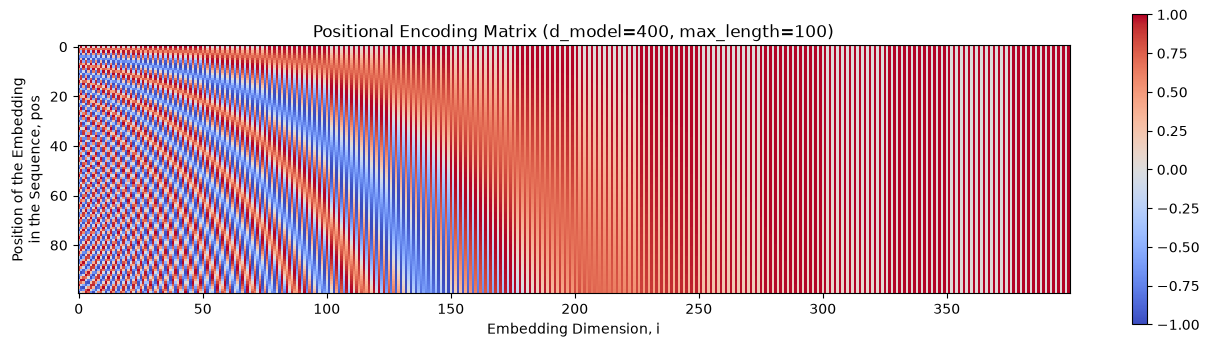

In [3]:
import matplotlib.pyplot as plt

# Instantiate a PositionalEncoder class
d_model = 400
max_length = 100
rounding = 4

PE = PositionalEncoder(d_model=d_model,
                       max_length=max_length,
                       rounding=rounding)

# Generate positional encodings
input = np.round(np.random.rand(max_length, d_model), 4)
positional_encoding = PE.generate_positional_encoding()

# Plot positional encodings
cax = plt.matshow(positional_encoding, cmap='coolwarm')
plt.title(f'Positional Encoding Matrix ({d_model=}, {max_length=})')
plt.ylabel('Position of the Embedding\nin the Sequence, pos')
plt.xlabel('Embedding Dimension, i')
plt.gcf().colorbar(cax)
plt.gca().xaxis.set_ticks_position('bottom')